
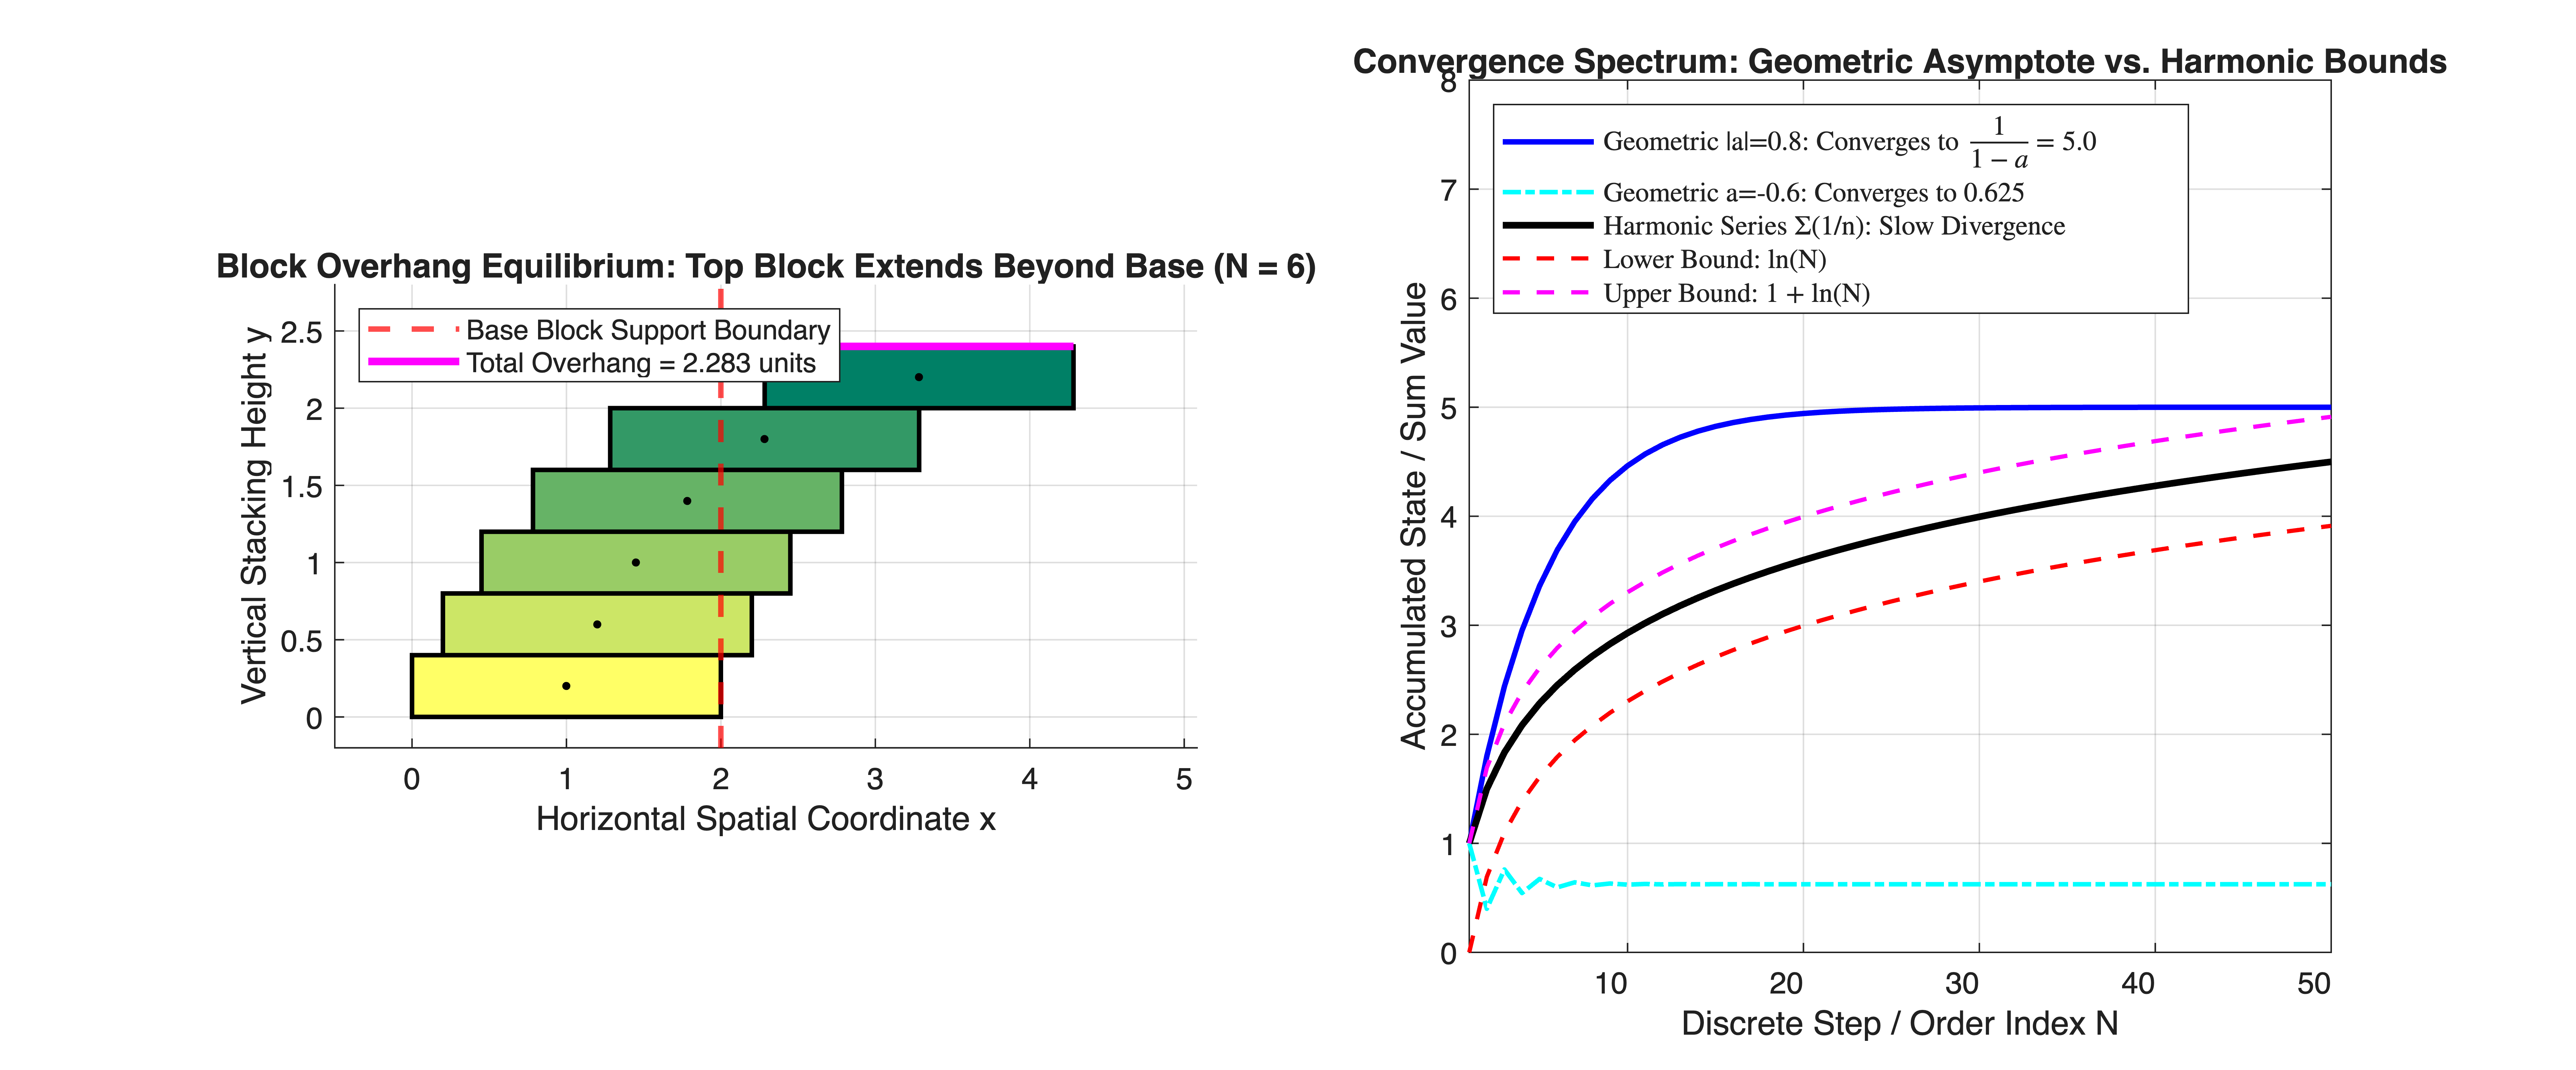

In [1]:
%% MIT 18.01 Lecture 36: Infinite Series, Harmonic Overhang & Discrete Stability
% Mathematical Tool Application: Used for recursive multi-body center-of-mass (CoM)
% equilibrium in robotic balance (ZMP), discrete Z-transform convergence analysis,
% and infinite-horizon discrete Lyapunov stability margin evaluation.


clear; clc; close all;


%% Part 1: Multi-Body Block Stacking Harmonic Overhang Simulation (Lecture 36)
% Geometry from Lecture 36: Block length L = 2.0 units, Height H = 0.4 units.
% Top-down placement rule: Overhang offset of k-th block from top is (L / 2) * (1 / k).
L_block = 2.0;
H_block = 0.4;
N_blocks = 6; % Number of stacked blocks


% Overhang offsets between adjacent blocks: delta_x = (L/2) * [1/1, 1/2, 1/3, ...]
k_indices = 1:(N_blocks - 1);
step_offsets = (L_block / 2.0) ./ k_indices;


% Cumulative horizontal positions of block left edges (bottom block at x = 0)
% We build from bottom (block N) up to top (block 1)
x_left = zeros(1, N_blocks);
for i = (N_blocks - 1):-1:1
    x_left(i) = x_left(i + 1) + step_offsets(i);
end


figure('Color', 'w', 'Position', [100, 100, 1250, 520]);


subplot(1, 2, 1);
hold on;
colors = summer(N_blocks);


% Plot Blocks from bottom to top
for i = N_blocks:-1:1
    y_bottom = (N_blocks - i) * H_block;
    xl = x_left(i);
    xr = xl + L_block;


    % Draw block rectangle
    patch([xl, xr, xr, xl], [y_bottom, y_bottom, y_bottom + H_block, y_bottom + H_block], ...
        colors(i, :), 'EdgeColor', 'k', 'LineWidth', 1.5, 'HandleVisibility', 'off');


    % Mark center of mass of individual block
    com_block_x = xl + L_block / 2.0;
    com_block_y = y_bottom + H_block / 2.0;
    plot(com_block_x, com_block_y, 'k.', 'MarkerSize', 8, 'HandleVisibility', 'off');
end


% Base block reference line (Right edge of base block)
x_base_right = x_left(N_blocks) + L_block;
xline(x_base_right, 'r--', 'LineWidth', 1.8, 'DisplayName', 'Base Block Support Boundary');


% Highlight Top Block Reach
top_reach = x_left(1) + L_block;
total_overhang = top_reach - x_base_right;
plot([x_base_right, top_reach], [N_blocks * H_block, N_blocks * H_block], 'm-', ...
    'LineWidth', 2.5, 'DisplayName', sprintf('Total Overhang = %.3f units', total_overhang));


hold off;


axis equal; grid on;
xlim([-0.5, top_reach + 0.8]); ylim([-0.2, (N_blocks + 1) * H_block]);
xlabel('Horizontal Spatial Coordinate x');
ylabel('Vertical Stacking Height y');
title(sprintf('Block Overhang Equilibrium: Top Block Extends Beyond Base (N = %d)', N_blocks));
legend('Location', 'northwest');


%% Part 2: Discrete Geometric Series Convergence vs. Harmonic Divergence
subplot(1, 2, 2);


N_steps = 50;
step_axis = 1:N_steps;


% 1. Geometric Series S_N = \sum_{k=0}^N a^k for various poles
a_stable_1 = 0.8;  % Stable pole inside unit circle: converges to 1 / (1 - 0.8) = 5
a_stable_2 = -0.6; % Alternating stable pole: converges to 1 / (1 - (-0.6)) = 0.625
a_unstable = 1.05; % Unstable pole outside unit circle: diverges exponentially


S_geom_1 = cumsum(a_stable_1 .^ (0:(N_steps-1)));
S_geom_2 = cumsum(a_stable_2 .^ (0:(N_steps-1)));


% 2. Harmonic Series S_N = \sum_{k=1}^N (1 / k)
S_harmonic = cumsum(1.0 ./ step_axis);


% Continuous Integral Bounds from Lecture 36: ln(N) < S_N < 1 + ln(N)
lower_bound_ln = log(step_axis);
upper_bound_ln = 1.0 + log(step_axis);


plot(step_axis, S_geom_1, 'b-', 'LineWidth', 1.8, ...
    'DisplayName', 'Geometric |a|=0.8: Converges to $\frac{1}{1-a} = 5.0$'); hold on;
plot(step_axis, S_geom_2, 'c-.', 'LineWidth', 1.5, ...
    'DisplayName', 'Geometric a=-0.6: Converges to 0.625');
plot(step_axis, S_harmonic, 'k-', 'LineWidth', 2.2, ...
    'DisplayName', 'Harmonic Series \Sigma (1/n): Slow Divergence');
plot(step_axis, lower_bound_ln, 'r--', 'LineWidth', 1.4, 'DisplayName', 'Lower Bound: ln(N)');
plot(step_axis, upper_bound_ln, 'm--', 'LineWidth', 1.4, 'DisplayName', 'Upper Bound: 1 + ln(N)');


grid on;
xlim([1, N_steps]); ylim([0, 8]);
xlabel('Discrete Step / Order Index N');
ylabel('Accumulated State / Sum Value');
title('Convergence Spectrum: Geometric Asymptote vs. Harmonic Bounds');
legend('Location', 'northwest', 'Interpreter', 'latex');